### Model Setup

In [11]:
from PIL import Image
import os 
os.environ['CUDA_VISIBLE_DEVICES'] = '4'
import torch
import argparse
from modeling.BaseModel import BaseModel
from modeling import build_model
from utilities.distributed import init_distributed
from utilities.arguments import load_opt_from_config_files
from utilities.constants import PATHSEG_CLASSES

from inference_utils.inference import interactive_infer_image

# Build model config
def parse_option():
    parser = argparse.ArgumentParser('PathSegmentor Demo', add_help=False)
    parser.add_argument('--conf_files', default="configs/pathsegmentor_inference.yaml", metavar="FILE", help='path to config file', )
    parser.add_argument('--model_path', default="/jhcnas5/chenzhixuan/MyOpenSource/huggingface/PathSegmentor/model_state_dict.pt", metavar="FILE", help='path to model file')
    cfg = parser.parse_args()
    return cfg

# print(cfg.conf_files)
# cfg = parse_option()
opt = load_opt_from_config_files(["configs/pathsegmentor_inference.yaml"])
opt = init_distributed(opt)

# Load model from pretrained weights
pretrained_pth = '/jhcnas5/chenzhixuan/MyOpenSource/huggingface/PathSegmentor/model_state_dict.pt'

model = BaseModel(opt, build_model(opt)).from_pretrained(pretrained_pth).eval().cuda()
with torch.no_grad():
    model.model.sem_seg_head.predictor.lang_encoder.get_text_embeddings(PATHSEG_CLASSES + ["background"], is_eval=True)

$UNUSED$ criterion.empty_weight, Ckpt Shape: torch.Size([21])


### Utility Functions

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from skimage.morphology import binary_erosion

def plot_segmentation_masks(original_image, segmentation_masks, texts, 
                            colors=None, alpha=0.6, boundary_thickness=3, gt_masks=None):
    ''' 
    分别绘制原图、预测掩码和 GT 掩码叠加图（每行三张图），颜色相同但分图显示。
    
    参数:
        original_image (ndarray): 原始图像，RGB格式
        segmentation_masks (list): 预测掩码列表
        texts (list): 每个掩码的文本标签
        colors (list): 每个掩码使用的颜色，默认为红色
        alpha (float): 掩码透明度
        boundary_thickness (int): 边界线粗细
        gt_masks (list, optional): 与 segmentation_masks 一一对应的 GT 掩码列表
    '''
    original_image = original_image[:, :, :3].astype(np.uint8)

    if colors is None:
        colors = [[255, 0, 0]] * len(segmentation_masks)

    num_cols = 3 if gt_masks is not None else 2
    fig, ax = plt.subplots(len(segmentation_masks), num_cols, figsize=(4 * num_cols, 4 * len(segmentation_masks)))

    if len(segmentation_masks) == 1:
        ax = np.expand_dims(ax, axis=0)  # 保证二维索引兼容性

    for i, (pred_mask, label) in enumerate(zip(segmentation_masks, texts)):
        mask_color = np.array(colors[i]).reshape(1, 1, 3)

        # ----------------- 原图 -----------------
        ax[i][0].imshow(original_image)
        ax[i][0].set_title('Original Image')
        ax[i][0].axis('off')

        # ----------------- Pred 图 -----------------
        pred_binary = pred_mask > 0.5
        pred_overlay = original_image.copy()

        # Alpha blending
        pred_overlay[pred_binary] = (
            (1 - alpha) * pred_overlay[pred_binary] + alpha * mask_color
        ).astype(np.uint8)

        # Pred 边界
        current_mask = pred_binary.copy()
        pred_boundary = np.zeros_like(pred_binary)
        for _ in range(boundary_thickness):
            eroded = binary_erosion(current_mask)
            boundary = current_mask & (~eroded)
            pred_boundary |= boundary
            current_mask = eroded

        pred_overlay[pred_boundary] = mask_color
        ax[i][1].imshow(pred_overlay)
        ax[i][1].set_title('Pred Mask')
        ax[i][1].axis('off')

        # ----------------- GT 图 -----------------
        if gt_masks is not None:
            gt_mask = gt_masks[i] > 0.5
            gt_overlay = original_image.copy()

            # Alpha blending
            gt_overlay[gt_mask] = (
                (1 - alpha) * gt_overlay[gt_mask] + alpha * mask_color
            ).astype(np.uint8)

            # GT 边界
            current_gt = gt_mask.copy()
            gt_boundary = np.zeros_like(gt_mask)
            for _ in range(boundary_thickness):
                eroded_gt = binary_erosion(current_gt)
                boundary = current_gt & (~eroded_gt)
                gt_boundary |= boundary
                current_gt = eroded_gt

            gt_overlay[gt_boundary] = mask_color
            ax[i][2].imshow(gt_overlay)
            ax[i][2].set_title('GT Mask')
            ax[i][2].axis('off')

    plt.tight_layout()
    plt.show()

# Example Inference

In [13]:
import json
import matplotlib.pyplot as plt

from inference_utils.processing_utils import read_rgb


def inference_rgb(file_path, text_prompts):
    image = read_rgb(file_path)
    
    pred_mask = interactive_infer_image(model, Image.fromarray(image), text_prompts)
    
    return image, pred_mask

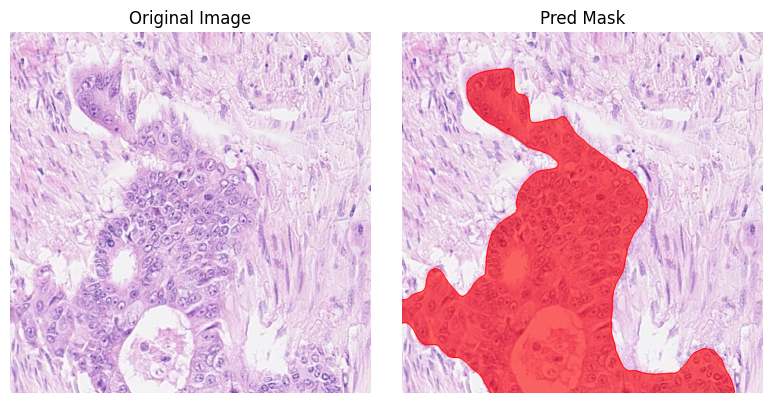

In [14]:

# Pathology Example
image_path = '/home/chenzhixuan/Workspace/PathSegmentor/examples/1_irregular/2/test181_pathology_colon.png'
mask_path = '/home/chenzhixuan/Workspace/PathSegmentor/examples/1_irregular/2/test181_pathology_colon_tissue+gland.png'
text_prompt = ['tissue-level gland in colon pathology']

image, pred_mask = inference_rgb(image_path, text_prompt)
gt_mask = read_rgb(mask_path)
gt_mask = gt_mask[:, :, 0]  # Assuming the GT mask is a single channel

colors = [[255, 0, 0]]

# Plot feature over image
plot_segmentation_masks(image, pred_mask, text_prompt, colors = colors)